# Curve build by interpolation method

Builds the curves from the local snapshot with every `PillarCurve` interpolation method, used for both the
index and the discount curves, and compares them.

- **Build error**: sum of the absolute CLP MTM of every input quote on the final curves. It is split into the
  quotes that were fitted and the redundant quotes the build ditched.
- **Build time**: `build_curves` alone, 10 heat-up runs discarded and then the mean of 20 runs. Each run gets a
  fresh market, loaded outside the timer.
- **Valuation error**: booked swap against its stored MTMs, as in `run_valuation.py`. `diff (bp)` is the difference
  over the net DV01 of the fixed legs.
- **Plot**: ICP curve. Red is the average forward of each segment and blue the instantaneous forward, measured as
  the one-day forward. Both are continuously compounded, Act/365.

In [1]:
import warnings
from datetime import date, timedelta
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from fintoolsom.curve_builder import (
    InsufficientQuotesError,
    RedundantQuoteWarning,
    RepricingError,
    build_curves,
)
from fintoolsom.derivatives import Calculator
from fintoolsom.derivatives.swaps import FloatingLeg, LegSide
from fintoolsom.market import (
    CrossCurrencyFloatFloatQuote,
    Currency,
    ForwardPointsQuote,
)
from fintoolsom.rates import PillarCurve

from build_quotes import fixings_start, get_market_and_quotes
from build_swap import get_swap
from stored_values import stored_mtm

VALUATION_DATE = date(2026, 11, 6)
SWAP_ID = 10
COLLATERAL = 1  # 1 = SOFR collateralised, 0 = uncollateralised
COLLATERAL_CUTOFF_MONTHS = 24
HEAT_UP_RUNS = 10
TIMED_RUNS = 20
METHODS = sorted(PillarCurve.allowed_methods, key=lambda method: method.value)
BUILD_ERRORS = (InsufficientQuotesError, RepricingError, ValueError)

In [2]:
def fresh_inputs():
    start = get_swap(SWAP_ID, collateral=COLLATERAL).start_date
    return get_market_and_quotes(
        VALUATION_DATE,
        fixings_start(start, VALUATION_DATE),
        collateral_cutoff_months=COLLATERAL_CUTOFF_MONTHS,
    )


def build(inputs, method):
    build_curves(
        inputs.quotes,
        inputs.market,
        interp_method=method,
    )


def quote_mtm(quote, market):
    needs_market = isinstance(quote, (CrossCurrencyFloatFloatQuote, ForwardPointsQuote))
    instrument = (
        quote.get_instrument(market) if needs_market else quote.get_instrument()
    )
    return Calculator.valuate(instrument, market, Currency.CLP)


def build_error(inputs, ditched):
    ditched_ids = {id(row[0]) for row in ditched}
    fitted, redundant = 0.0, 0.0
    for quote in inputs.quotes:
        error = abs(quote_mtm(quote, inputs.market))
        if id(quote) in ditched_ids:
            redundant += error
        else:
            fitted += error
    return {
        "total error (CLP)": fitted + redundant,
        "fitted quotes (CLP)": fitted,
        "ditched quotes (CLP)": redundant,
        "ditched count": len(ditched),
    }


def build_time_ms(method):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for _ in range(HEAT_UP_RUNS):
            build(fresh_inputs(), method)
        samples = []
        for _ in range(TIMED_RUNS):
            inputs = fresh_inputs()
            start = perf_counter()
            build(inputs, method)
            samples.append(perf_counter() - start)
    return {
        "mean time (ms)": 1000 * float(np.mean(samples)),
        "std time (ms)": 1000 * float(np.std(samples)),
    }


def leg_dv01(swap, side, market):
    if isinstance(swap.leg(side), FloatingLeg):
        return 0.0
    return Calculator.get_leg_dv01(swap, side, market, Currency.CLP)


def valuation_error(market):
    booked = get_swap(SWAP_ID, collateral=COLLATERAL)
    swap = booked.swap
    stored = stored_mtm(VALUATION_DATE, [booked.receive_leg_id, booked.pay_leg_id])
    mtm = Calculator.get_swap_mtm(swap, market, Currency.CLP)
    stored_total = sum(stored.values())
    dv01 = leg_dv01(swap, LegSide.RECEIVE, market) - leg_dv01(swap, LegSide.PAY, market)
    receive_pv = Calculator.get_leg_pv(swap, LegSide.RECEIVE, market, Currency.CLP)
    pay_pv = Calculator.get_leg_pv(swap, LegSide.PAY, market, Currency.CLP)
    return {
        "MTM (CLP)": mtm,
        "stored MTM (CLP)": stored_total,
        "diff (CLP)": mtm - stored_total,
        "diff (bp)": (mtm - stored_total) / dv01,
        "receive leg diff (CLP)": receive_pv - stored[booked.receive_leg_id],
        "pay leg diff (CLP)": pay_pv + stored[booked.pay_leg_id],
    }


def one_day_forwards(curve):
    start = curve.knot_dates[0]
    days = (curve.last_date - start).days
    dates = [start + timedelta(days=n) for n in range(days + 1)]
    return dates[:-1], -np.diff(np.log(curve.get_dfs(dates))) * 365

In [3]:
def evaluate(method):
    inputs = fresh_inputs()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        build(inputs, method)
    ditched = [
        row
        for warning in caught
        if issubclass(warning.category, RedundantQuoteWarning)
        for row in warning.message.ditched
    ]
    icp = inputs.market.curves["ICP"]
    return {
        "build": build_error(inputs, ditched) | build_time_ms(method),
        "valuation": valuation_error(inputs.market),
        "icp": {
            "knots": icp.knot_dates,
            "averages": np.array(icp.forward_rates),
            "one_day": one_day_forwards(icp),
        },
    }


results, failures = {}, {}
for method in METHODS:
    try:
        results[method] = evaluate(method)
    except BUILD_ERRORS as error:
        failures[method.name] = f"{type(error).__name__}: {error}"
for name, message in failures.items():
    print(f"{name} failed. {message}")

## Curve building: error and time

In [4]:
def formatted(rows, formats):
    frame = pd.DataFrame(rows).T
    return frame.astype(object).apply(
        lambda column: column.map(formats[column.name].format)
    )


display(
    formatted(
        {method.name: result["build"] for method, result in results.items()},
        {
            "total error (CLP)": "{:.2e}",
            "fitted quotes (CLP)": "{:.2e}",
            "ditched quotes (CLP)": "{:.2e}",
            "ditched count": "{:.0f}",
            "mean time (ms)": "{:,.1f}",
            "std time (ms)": "{:,.1f}",
        },
    )
)

,total error (CLP),fitted quotes (CLP),ditched quotes (CLP),ditched count,mean time (ms),std time (ms)
HermiteCubicSpline,7.79e-10,7.79e-10,0.00e+00,0,354.5,2.8
PiecewiseConstant,7.32e-09,7.32e-09,0.00e+00,0,60.6,0.6
PiecewiseLinear,3.85e-08,3.85e-08,0.00e+00,0,113.0,1.7
CubicSpline,7.38e-10,7.38e-10,0.00e+00,0,346.2,8.5
ConvexMonotone,6.48e-10,6.48e-10,0.00e+00,0,369.3,3.8


## Valuation error

In [5]:
display(
    formatted(
        {method.name: result["valuation"] for method, result in results.items()},
        {
            "MTM (CLP)": "{:,.0f}",
            "stored MTM (CLP)": "{:,.0f}",
            "diff (CLP)": "{:,.0f}",
            "diff (bp)": "{:+.3f}",
            "receive leg diff (CLP)": "{:,.0f}",
            "pay leg diff (CLP)": "{:,.0f}",
        },
    )
)

,MTM (CLP),stored MTM (CLP),diff (CLP),diff (bp),receive leg diff (CLP),pay leg diff (CLP)
HermiteCubicSpline,"-55,594,082","-60,130,757","4,536,675",-1.054,"-3,773,512","-8,310,188"
PiecewiseConstant,"-60,255,566","-60,130,757","-124,809",+0.029,"-7,559,206","-7,434,397"
PiecewiseLinear,"-43,121,901","-60,130,757","17,008,856",-3.966,"-60,097,972","-77,106,828"
CubicSpline,"-52,230,120","-60,130,757","7,900,637",-1.836,"-6,160,223","-14,060,861"
ConvexMonotone,"-56,764,787","-60,130,757","3,365,970",-0.782,"-3,847,291","-7,213,260"


## ICP forwards

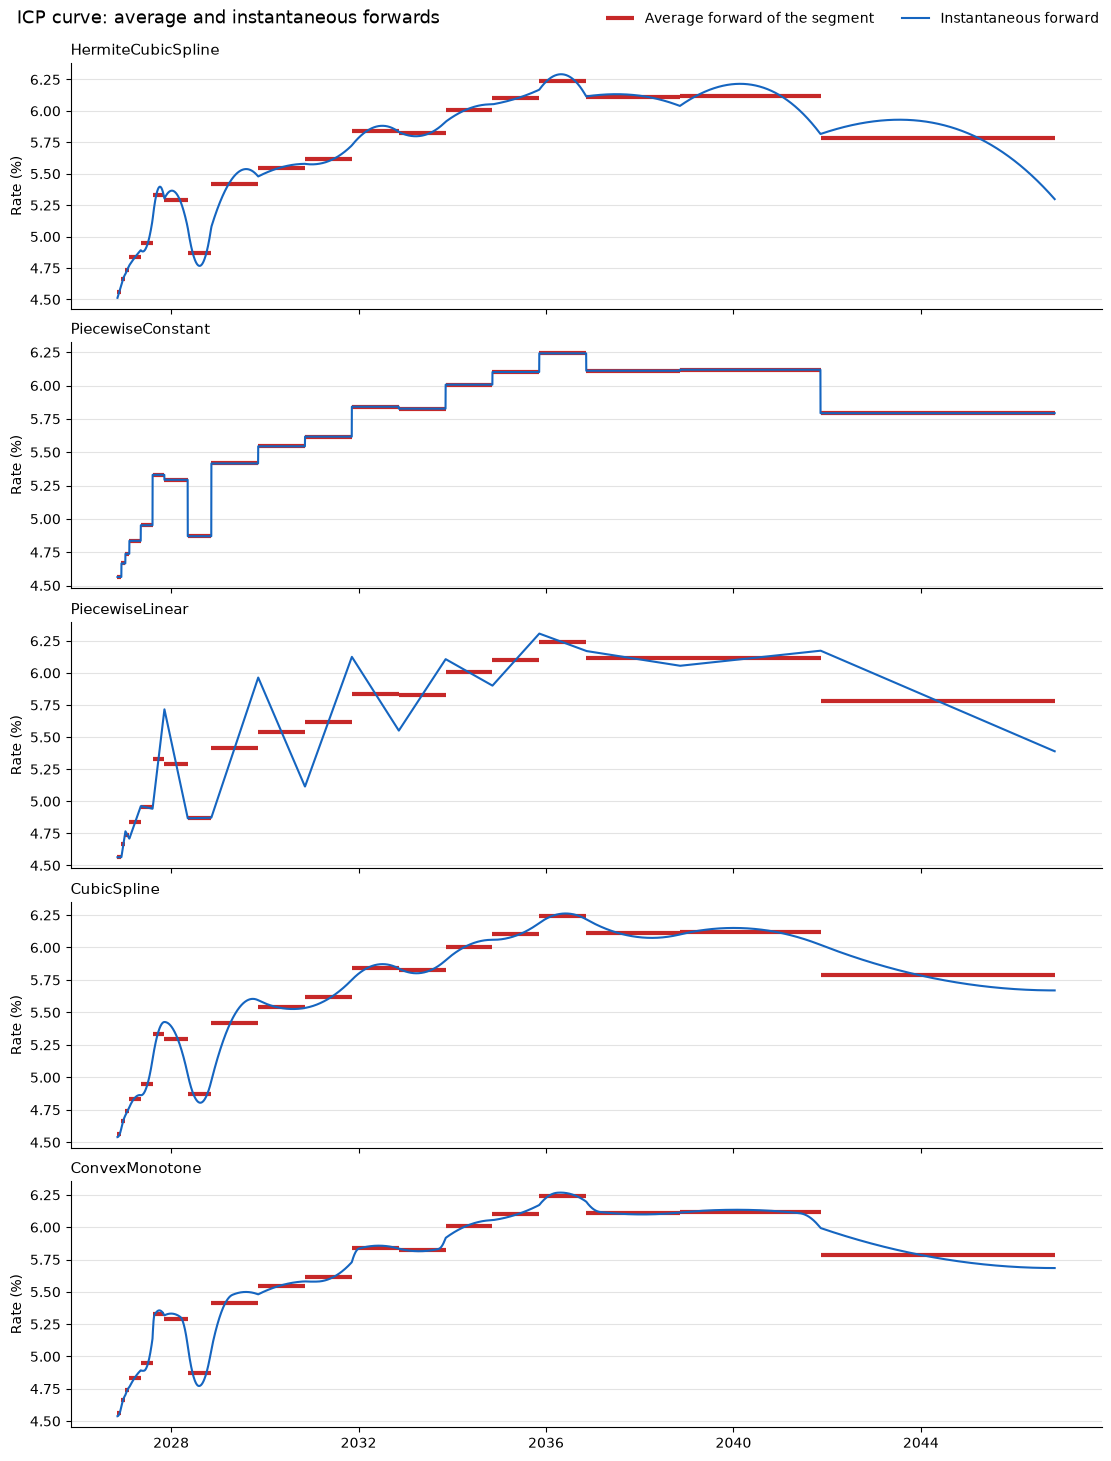

In [6]:
AVERAGE_COLOR, INSTANT_COLOR = "#C62828", "#1565C0"

fig, axes = plt.subplots(
    len(results), 1, figsize=(11, 2.9 * len(results)), sharex=True, layout="constrained"
)
for ax, (method, result) in zip(np.atleast_1d(axes), results.items()):
    icp = result["icp"]
    dates, one_day = icp["one_day"]
    ax.hlines(
        100 * icp["averages"],
        icp["knots"][:-1],
        icp["knots"][1:],
        colors=AVERAGE_COLOR,
        linewidth=3,
        label="Average forward of the segment",
    )
    ax.plot(
        dates,
        100 * one_day,
        color=INSTANT_COLOR,
        linewidth=1.5,
        label="Instantaneous forward",
    )
    ax.set_title(method.name, loc="left", fontsize=11)
    ax.set_ylabel("Rate (%)")
    ax.grid(axis="y", color="#E3E3E3", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
handles, labels = np.atleast_1d(axes)[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper right", ncols=2, frameon=False)
fig.suptitle(
    "ICP curve: average and instantaneous forwards", x=0.01, ha="left", fontsize=13
)
plt.show()